<a href="https://colab.research.google.com/github/ahmed-abo-el3ela/assymint-of-data-science-code/blob/main/ML%20for%20Salary_Data_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns  #vizuli
import matplotlib.pyplot as plt   #vizuli
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split  #تقسيم الداتا
from sklearn.metrics import mean_squared_error ,r2_score ,mean_absolute_error

#from sklearn.linear_model import LogisticRegression
#from sklearn.metrics import accuracy_score
#from matplotlib import pyplot as plt
#from sklearn.model_selection import train_test_split
#from sklearn.linear_model import LogisticRegression
#from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv('/content/Salary_Data.csv')

In [ ]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
df.describe() #statical

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [ ]:
# name of coloum
df.columns

Index(['YearsExperience', 'Salary'], dtype='object')

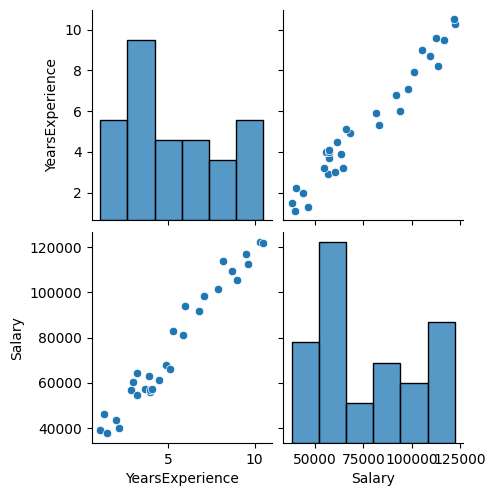

In [ ]:
#sketch per plot
sns.pairplot(df)

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 100x100 with 0 Axes>

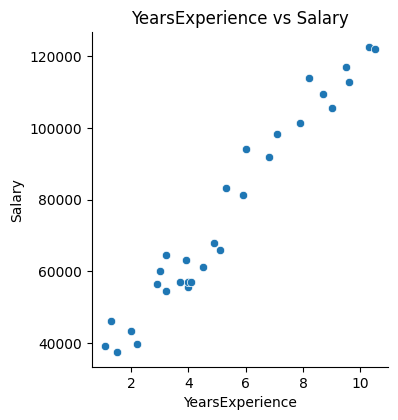

In [ ]:
plt.figure(figsize=(1,1))
sns.pairplot(df , x_vars=['YearsExperience'] ,
             y_vars=['Salary'] , size=4,
             kind='scatter')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('YearsExperience vs Salary')
plt.show()

#split data

In [ ]:
x = df['YearsExperience']
y = df['Salary']

In [ ]:
x = df.iloc[:,:-1]
#هاتلي الروز كلها و الكولوم من اول 0لحد اخر واحد
#-1 يعني كله هاته عدا اول واحد / او استبعد اخر واحد
y = df.iloc[:,1]
#1 هات اخر واحد
x.head()

,YearsExperience
0,1.1
1,1.3
2,1.5
3,2.0
4,2.2


In [ ]:
# تقسيم الداتا
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

#build model

In [ ]:
model = LinearRegression()
#تطبيق الموديل علي الداتا
model.fit(x_train , y_train)

LinearRegression()

#predict test

In [ ]:
y_predict = model.predict(x_test)
y_predict
#قيم توقعتها

array([115790.21011287,  71498.27809463, 102596.86866063,  75267.80422384,
        55477.79204548,  60189.69970699])

#evaluation

In [ ]:
r2_score(y_test , y_predict)
#عايز تشوف انت صح ولالا
#y_test اللي عندك // y_predict التوقع اللي طلع
#فبنقارن م بينهم

0.9024461774180497

#لحساب ال error

In [ ]:
mean_squared_error(y_test , y_predict)

49830096.85590839

In [ ]:
np.sqrt(mean_squared_error(y_test , y_predict))

np.float64(7059.04362190151)

In [ ]:
mean_absolute_error(y_test , y_predict)

6286.453830757749

In [ ]:
# لو عايز اوصل لقيم المعادله  M//B
#B  (y=mx+b)
model.intercept_

np.float64(25321.583011776813)

In [ ]:
#M = slope
model.coef_

array([9423.81532303])

#لحساب عدد سنين انا عايزها

In [ ]:
def calc_sal(exp):

  return model.coef_ * exp + model.intercept_

In [ ]:
calc_sal(1.5)

array([39457.30599632])